# Response of the redshift-space power spectrum

Maps of how the galaxy power spectrum a survey observes responds to each parameter.

A survey observes the spectrum as a function of the wave number and of $\mu$, the cosine of the angle to the line of sight. Two effects make it anisotropic. Peculiar velocities add the Kaiser factor,

$$
P_g(k, \mu) = (b + f \mu^2)^2 P(k),
$$

and the survey turns redshifts and angles into distances with a reference cosmology, which rescales the true wave numbers (Alcock-Paczynski):

$$
P_\mathrm{obs}(k_\mathrm{ref}, \mu_\mathrm{ref}) = \frac{P_g(k, \mu)}{q_\perp^2 q_\parallel}, \qquad
q_\perp = \frac{D_A}{D_{A,\mathrm{ref}}}, \qquad
q_\parallel = \frac{H_\mathrm{ref}}{H} .
$$

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import LCDM, solve_eb

REDSHIFT = 1.0
K = np.geomspace(1.0e-4, 1.0, 128)  # wave numbers of the solve, 1/Mpc
K_REF = K[4:-4]  # of the map: the rescaled ones stay inside the solve's
MU = np.linspace(0.0, 1.0, 65)

## The cosmology and its parameters

The Planck 2018 best fit is the reference, given by $\Omega_m$, $\Omega_b$ and $H_0$, which `from_density_parameters` turns into the model's physical densities. The parameters are five of the cosmology and the galaxy bias, $b = 1.5$.

In [2]:
h = 0.6732117
PLANCK = dict(
    Omegam=(0.02238280 + 0.1201075) / h**2,
    Omegab=0.02238280 / h**2,
    H0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    Tcmb=2.7255,
    YHe=0.2454006,
    Neff=3.046,
)
PARAMETERS = {  # key: label; the last is the galaxy bias
    "H0": "H_0",
    "Omegam": r"\Omega_m",
    "Omegab": r"\Omega_b",
    "Neff": r"N_\mathrm{eff}",
    "n_s": "n_s",
    "bias": "b",
}
theta = jnp.asarray([PLANCK[key] for key in list(PARAMETERS)[:-1]] + [1.5])

## Save points

`solve_eb` integrates in the scale factor and differentiates at fixed scale factor. It saves at the sample's redshift and today, and every derivative below is at fixed redshift.

In [3]:
A_SAMPLE = 1.0 / (1.0 + REDSHIFT)

## Linear theory at the redshift

Everything comes from one `solve_eb`. The density contrasts and their rates give $P$ and the growth rate

$$
f = -\frac{k \, (z + f_b v_b)}{a H \, \delta}, \qquad f_b = \frac{\omega_b}{\omega_c + \omega_b},
$$

the expansion rate `adotoa` gives $a H$, and the conformal time `tau`, a state of the solve, gives the comoving distance $\tau_0 - \tau(a)$ between its values today and at the sample.

In [4]:
def linear_theory(cosmology):
    """``P(k)``, the growth rate ``f(k)``, the comoving distance and ``a H`` at the redshift."""

    values = solve_eb(
        cosmology,
        K,
        [A_SAMPLE, 1.0],
        keep=("clxc", "clxb", "z", "vb", "adotoa", "tau"),
    )
    clxc, clxb, z, vb, adotoa, tau = values[0, :, :, 0]  # each (k,), at the redshift
    tau0 = values[0, -1, 0, -1]  # the conformal time today

    f_b = cosmology.omega_b / (cosmology.omega_c + cosmology.omega_b)
    delta = (1.0 - f_b) * clxc + f_b * clxb
    growth_rate = -K * (z + f_b * vb) / (adotoa * delta)
    primordial = cosmology.A_s * (K / cosmology.k_p) ** (cosmology.n_s - 1.0)
    pk = 2.0 * jnp.pi**2 / K**3 * primordial * delta**2
    return pk, growth_rate, tau0 - tau[0], adotoa[0]

The reference distance and expansion rate, which the survey assumes:

In [5]:
_, _, distance_ref, aH_ref = linear_theory(LCDM.from_density_parameters(**PLANCK))

## The observed spectrum

A reference $(k_\mathrm{ref}, \mu_\mathrm{ref})$ maps to the true

$$
k = \frac{k_\mathrm{ref}}{q_\perp} \sqrt{1 + \mu_\mathrm{ref}^2 \left(\frac{q_\perp^2}{q_\parallel^2} - 1\right)},
\qquad
\mu = \mu_\mathrm{ref} \, \frac{q_\perp}{q_\parallel} \left[1 + \mu_\mathrm{ref}^2 \left(\frac{q_\perp^2}{q_\parallel^2} - 1\right)\right]^{-1/2} .
$$

In [6]:
def observed_power(theta):
    """``P_obs(k_ref, mu_ref)`` in Mpc^3, ``(len(K_REF), len(MU))``."""

    *cosmological, bias = theta
    pk, growth_rate, distance, aH = linear_theory(
        LCDM.from_density_parameters(
            **{**PLANCK, **dict(zip(PARAMETERS, cosmological))}
        )
    )
    q_perp, q_par = distance / distance_ref, aH_ref / aH
    stretch = jnp.sqrt(1.0 + MU**2 * ((q_perp / q_par) ** 2 - 1.0))
    k = K_REF[:, None] / q_perp * stretch  # the true wave number and angle
    mu = MU * q_perp / q_par / stretch
    pk = jnp.exp(jnp.interp(jnp.log(k), np.log(K), jnp.log(pk)))
    growth_rate = jnp.interp(jnp.log(k), np.log(K), growth_rate)
    return (bias + growth_rate * mu**2) ** 2 * pk / (q_perp**2 * q_par)

## The response

$\partial \ln P_\mathrm{obs} / \partial \ln p$ over the $(k, \mu)$ plane, from one `jax.jacfwd`.

In [7]:
power = observed_power(theta)
jacobian = jax.jacfwd(observed_power)(theta)  # (k, mu, parameter)
response = np.asarray(theta * jacobian / power[..., None])  # d ln P / d ln p

In [8]:
print(f"d ln P_obs / d ln p at z = {REDSHIFT}, across (mu = 0) and along (mu = 1)")
print(f"{'k [1/Mpc]':>10}  {'mu':>3}" + "".join(f"{key:>9}" for key in PARAMETERS))
for i in range(6, len(K_REF), 22):
    for j in (0, -1):
        row = "".join(f"{v:9.3f}" for v in response[i, j])
        print(f"{K_REF[i]:10.3e}  {MU[j]:3.0f}{row}")

d ln P_obs / d ln p at z = 1.0, across (mu = 0) and along (mu = 1)
 k [1/Mpc]   mu       H0   Omegam   Omegab     Neff      n_s     bias
 2.065e-04    0   -0.027   -0.991    0.000   -0.001   -5.303    2.000
 2.065e-04    1   -0.029   -0.710    0.000   -0.001   -5.303    1.262
 1.018e-03    0    0.024   -0.947    0.000   -0.013   -3.762    2.000
 1.018e-03    1    0.024   -0.674    0.000   -0.013   -3.762    1.262
 5.021e-03    0    0.371   -0.655   -0.003   -0.097   -2.221    2.000
 5.021e-03    1    0.371   -0.441   -0.003   -0.098   -2.221    1.263
 2.476e-02    0    1.347    0.608   -0.297   -0.297   -0.679    2.000
 2.476e-02    1    1.348    0.577   -0.297   -0.297   -0.679    1.263
 1.221e-01    0    2.374    1.635   -0.740   -0.552    0.862    2.000
 1.221e-01    1    2.375    1.568   -0.740   -0.553    0.862    1.263
 6.019e-01    0    2.876    2.256   -0.764   -0.558    2.404    2.000
 6.019e-01    1    2.877    2.013   -0.764   -0.558    2.404    1.263


## The maps

One polar "eye" per parameter: the angle to the line of sight goes around, with the line of sight pointing up, and $\log k$ goes outwards.

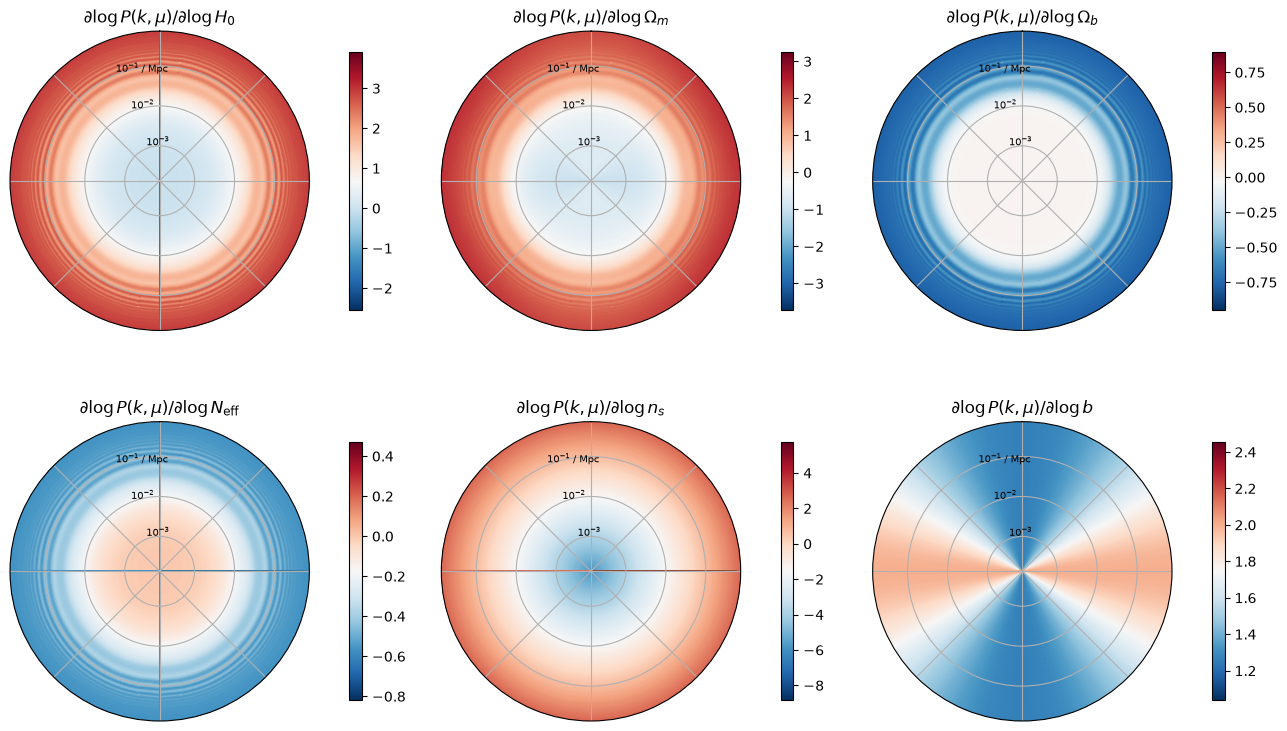

In [9]:
# One eye per parameter: the angle to the line of sight around, log k outwards.
angle = np.arccos(MU)
angle = np.concatenate(
    [angle, np.pi - angle[::-1], np.pi + angle, 2 * np.pi - angle[::-1]]
)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), subplot_kw={"projection": "polar"})
for i, (ax, label) in enumerate(zip(axes.flat, PARAMETERS.values())):
    quadrant = response[..., i]
    eye = np.concatenate([quadrant, quadrant[:, ::-1], quadrant, quadrant[:, ::-1]], 1)
    centre = np.median(quadrant)
    limit = 3.0 * np.std(quadrant) + 1.0e-3
    mesh = ax.pcolormesh(
        angle,
        np.log10(K_REF),
        eye,
        cmap="RdBu_r",
        vmin=centre - limit,
        vmax=centre + limit,
        shading="gouraud",
    )
    fig.colorbar(mesh, ax=ax, shrink=0.6, pad=0.1)
    ax.set_theta_zero_location("N")
    ax.set_xticklabels([])
    ax.set_rticks([-3, -2, -1])
    ax.set_yticklabels([r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$ / Mpc"], size=7)
    ax.set_title(rf"$\partial \log P(k, \mu) / \partial \log {label}$")
fig.tight_layout()
plt.show()